For time series analysis, the dataset choosen is "NEPSE Data" The different company's data were present among that I used "NLIC Stock Price Dataset" which contains 9 columns nad 3176 rows.

The dataset link is given as: https://github.com/Aabishkar2/nepse-data/blob/main/data/company-wise/NLIC.csv

In [ ]:
#Importing Necessary libraries required
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from scipy import stats
from google.colab import files
import warnings
warnings.filterwarnings('ignore')

#Data Processing



In [ ]:
from google.colab import files
uploaded = files.upload()

Saving NLIC.csv to NLIC (1).csv


In [ ]:
df = pd.read_csv('NLIC.csv')
print(df.dtypes)

published_date      object
open               float64
high               float64
low                float64
close              float64
per_change         float64
traded_quantity    float64
traded_amount      float64
status               int64
dtype: object


In [ ]:
rows, columns = df.shape
print("Number of rows: ", rows)
print("Number of columns: ", columns)

Number of rows:  3176
Number of columns:  9


In [ ]:
df

,published_date,open,high,low,close,per_change,traded_quantity,traded_amount,status
0,2011-03-29,725.0,725.0,725.0,725.0,NaN,60.0,43500.0,0
1,2011-03-31,725.0,715.0,715.0,715.0,-1.38,20.0,14300.0,0
2,2011-04-18,715.0,701.0,701.0,701.0,-1.96,450.0,315450.0,0
3,2011-04-27,701.0,701.0,701.0,701.0,0.00,30.0,21030.0,0
4,2011-05-02,701.0,687.0,648.0,648.0,-7.56,3083.0,2024499.0,0
...,...,...,...,...,...,...,...,...,...
3171,2025-11-27,843.0,857.9,841.1,849.7,0.41,120741.0,102439016.0,1
3172,2025-11-30,850.1,870.0,841.0,841.1,-1.01,217658.0,186501423.2,-1
3173,2025-12-01,825.0,854.0,825.0,840.0,-0.13,74629.0,62882662.5,1
3174,2025-12-02,841.0,849.0,838.1,839.2,-0.10,54611.0,45884346.8,-1


In [ ]:
#Sort by date
df = df.sort_values('published_date').reset_index(drop=True)
# Use 'close' as the primary series for analysis
series = df[['published_date', 'close']].copy()
# series = series.set_index('published_date').asfreq(None) # keep original irregular spacing
# Set index without trying to force a frequency
series = series.set_index('published_date')

# Check and fix duplicate dates
if not series.index.is_unique:
    print("Duplicate dates found. Fixing by averaging duplicates.")
    series = series.groupby(series.index).mean()

series['close'] = pd.to_numeric(series['close'], errors='coerce')
series = series.dropna()

Duplicate dates found. Fixing by averaging duplicates.


In [ ]:
# Create a time index t (integer) starting at 0 for regression/time computations
series = series.reset_index()
series['t'] = np.arange(len(series))

In [ ]:
# Maintain only 2 columns for simplicity
time_col = 'published_date'
value_col = 'close'
df = df[[time_col, value_col]].dropna().sort_values(by=time_col)
series = pd.Series(df[value_col].values, index=df[time_col])


print("\nTime range:", series.index.min(), "→", series.index.max())
print("Number of observations:", len(series))


Time range: 2011-03-29 → 2025-12-03
Number of observations: 3176


#Data Visualization

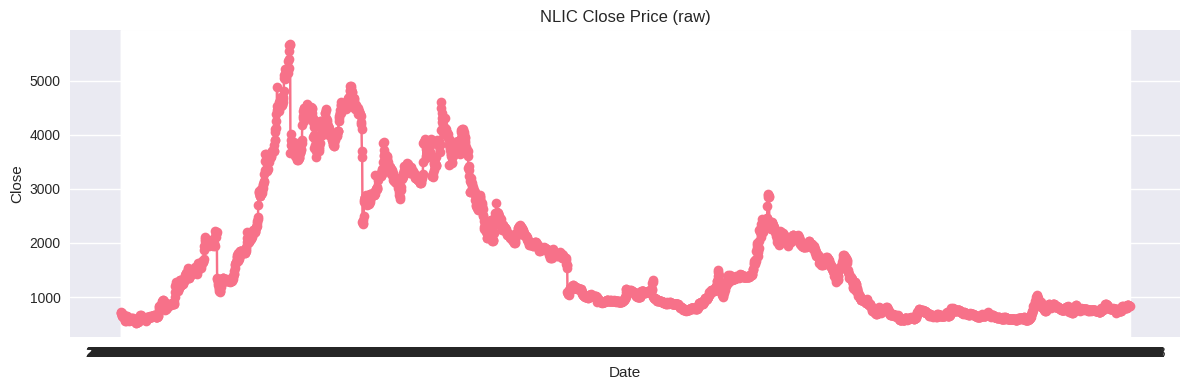

In [ ]:
# Plot raw series
plt.figure(figsize=(12,4))
plt.plot(series.index, series.values, marker='o')
plt.title('NLIC Close Price (raw)')
plt.xlabel('Date')
plt.ylabel('Close')
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

# Question Number 1: Trend Detection Method

In [ ]:
#2(a) Linear Regression y = b0 + b1*t + eps
#We'll compute slope, intercept, standard errors and t-test manually using numpy operations

y = series.values # Access the values directly from the Series
t = np.arange(len(series)).astype(float) # Generate integer time index
n = len(y)

In [ ]:
# Compute slope (b1) and intercept (b0)
mean_t = t.mean()
mean_y = y.mean()
S_tt = np.sum((t - mean_t)**2)
S_ty = np.sum((t - mean_t)*(y - mean_y))

b1 = S_ty / S_tt
b0 = mean_y - b1*mean_t

In [ ]:
# Residuals and variance
resid = y - (b0 + b1*t)
rss = np.sum(resid**2)
s2 = rss / (n - 2) # unbiased estimator of error variance

In [ ]:
# Standard error of b1
se_b1 = np.sqrt(s2 / S_tt)

t_stat_b1 = b1 / se_b1
p_value_b1 = 2 * (1 - stats.t.cdf(abs(t_stat_b1), df=n-2))

In [ ]:
# R-squared
ss_tot = np.sum((y - mean_y)**2)
R2 = 1 - rss/ss_tot

print('\nLinear Trend Results:')
print(f'b0 (intercept) = {b0:.6f}')
print(f'b1 (slope) = {b1:.6f}')
print(f'se(b1) = {se_b1:.6f}')
print(f't-stat (b1) = {t_stat_b1:.4f}')
print(f'p-value (b1) = {p_value_b1:.6f}')
print(f'R-squared = {R2:.4f}')


Linear Trend Results:
b0 (intercept) = 2903.982799
b1 (slope) = -0.719462
se(b1) = 0.019471
t-stat (b1) = -36.9497
p-value (b1) = 0.000000
R-squared = 0.3008


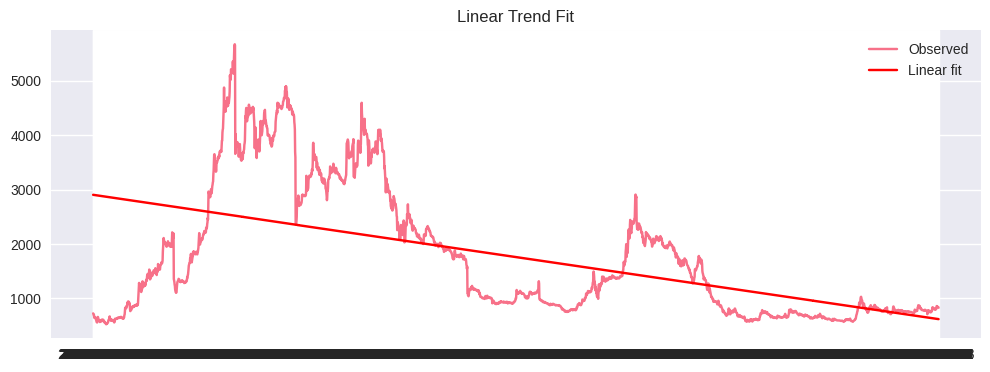

In [ ]:
# Plot the fitted line
plt.figure(figsize=(12,4))
plt.plot(series.index, y, label='Observed')
plt.plot(series.index, b0 + b1*t, label='Linear fit', color='red')
plt.legend()
plt.title('Linear Trend Fit')
plt.show()

In [ ]:
def tricube_weight(u):
    """Tri-cube weight function."""
    u = np.abs(u)
    w = np.where(u < 1, (1 - u**3)**3, 0.0)
    return w

In [ ]:
def loess(x, y, x_out, frac=0.3):
    """Compute LOESS smoothing for points x_out given data x,y and bandwidth fraction frac.
    We do local linear regression at each x_out point using tricube weights.
    """
    n = len(x)
    r = max(2, int(np.ceil(frac * n)))
    y_out = np.zeros(len(x_out))
    for i, xo in enumerate(x_out):
        # distances in index-space scaled by max distance within neighborhood
        distances = np.abs(x - xo)
        # pick r nearest points
        idx = np.argsort(distances)[:r]
        x_nb = x[idx]
        y_nb = y[idx]
        d_max = distances[idx[-1]]
        # avoid division by zero
        if d_max == 0:
          weights = np.ones_like(x_nb)
        else:
            u = distances[idx] / d_max
            weights = tricube_weight(u)
        # Weighted local linear regression: solve for beta in W*(y - X*beta) least squares
        X = np.vstack([np.ones(len(x_nb)), x_nb - xo]).T
        W = np.diag(weights)
        # beta = (X' W X)^(-1) X' W y
        try:
            XtWX = X.T @ W @ X
            XtWy = X.T @ W @ y_nb
            beta = np.linalg.solve(XtWX, XtWy)
            y_out[i] = beta[0] # prediction at xo (since second term multiplied by 0)
        except np.linalg.LinAlgError:
            # fall back to weighted mean
            y_out[i] = np.sum(weights * y_nb) / (np.sum(weights) + 1e-8)
    return y_out

Question Number 2: Apply LOESS smoothing with bandwidth parameters of 0.1, 0.3, and 0.5. Examine the smoothed curves for upward or downward patterns. Compare local behavior with global patterns. Explain that LOESS operates through local weighted polynomial regression.

# 1(b)LOESS Smoothing

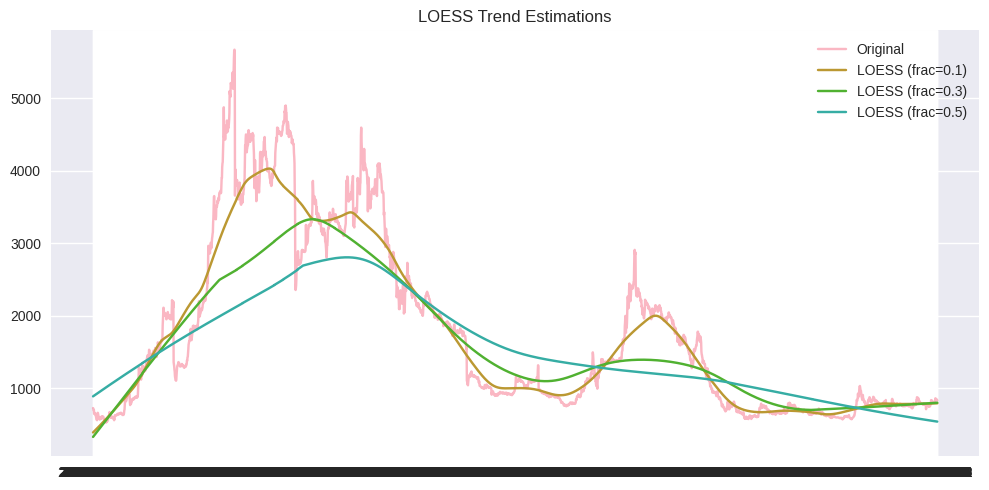

In [ ]:
bandwidths = [0.1, 0.3, 0.5]


plt.figure(figsize=(10,5))
plt.plot(series.index, series.values, label='Original', alpha=0.5)


for bw in bandwidths:
  smoothed = sm.nonparametric.lowess(series.values, t, frac=bw)[:,1]
  plt.plot(series.index, smoothed, label=f"LOESS (frac={bw})")

plt.legend()
plt.title("LOESS Trend Estimations")
plt.tight_layout()
plt.show()

#1(c) Mann-Kendall for non-parametric test for monotonic trends

In [ ]:
#Implement this non-parametric test for monotonic trends. Calculate the S statistic and corresponding p-value. Determine the direction of any detected trend (increasing or decreasing).

def mann_kendall_test(x):
    n = len(x)
    S = 0
    for i in range(n-1):
        S += np.sum(np.sign(x[i+1:] - x[i]))
        # Compute Var(S) accounting for ties
        unique, counts = np.unique(x, return_counts=True)
        tie_sum = np.sum(counts * (counts - 1) * (2*counts + 5))
        var_s = (n*(n-1)*(2*n+5) - tie_sum) / 18.0
        if S > 0:
            z = (S - 1) / np.sqrt(var_s)
        elif S < 0:
            z = (S + 1) / np.sqrt(var_s)
        else:
            z = 0.0
        p = 2 * (1 - stats.norm.cdf(abs(z)))
        trend = 'increasing' if z > 0 else ('decreasing' if z < 0 else 'no trend')
    return {'S': int(S), 'var_s': var_s, 'z': z, 'p_value': p, 'trend': trend}

mk_res = mann_kendall_test(y)
print('\nMann-Kendall Test Results:')
print(mk_res)


Mann-Kendall Test Results:
{'S': -2144885, 'var_s': np.float64(3561256807.6666665), 'z': np.float64(-35.941993668219574), 'p_value': np.float64(0.0), 'trend': 'decreasing'}


#Question Number1(d): Moving Average


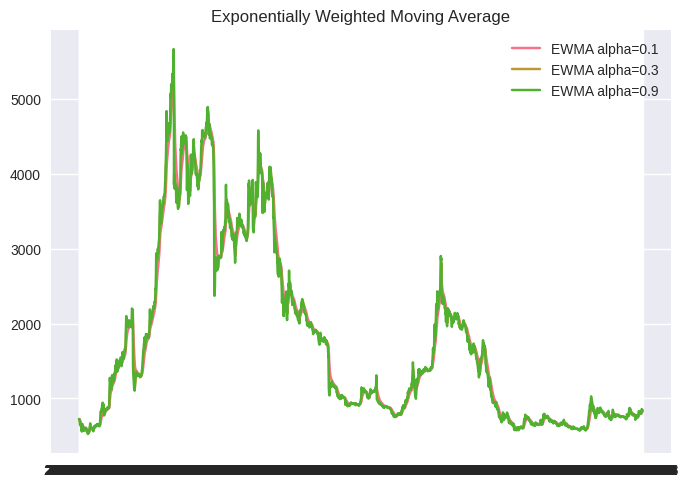

In [ ]:
#Exponentially Weighted Moving Average (EWMA) manual implementation
# alpha values: 0.1, 0.3, 0.9

def ewma(y, alpha):
    y_hat = np.zeros_like(y)
    y_hat[0] = y[0]
    for t_i in range(1, len(y)):
        y_hat[t_i] = alpha * y[t_i-1] + (1 - alpha) * y_hat[t_i-1]
    return y_hat

for alpha in [0.1, 0.3, 0.9]:
    plt.plot(series.index, ewma(y, alpha), label=f'EWMA alpha={alpha}')


plt.legend()
plt.title('Exponentially Weighted Moving Average')
plt.show()

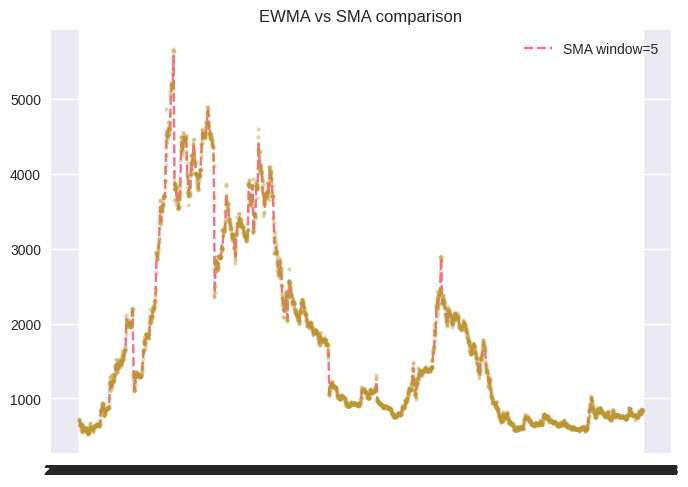

In [ ]:
# simple moving average for window=5 for comparison
window = 5
sma = pd.Series(y).rolling(window=window, min_periods=1, center=False).mean().values
plt.plot(series.index, sma, label=f'SMA window={window}', linestyle='--')
plt.plot(series.index, y, 'o', markersize=3, alpha=0.4)
plt.legend()
plt.title('EWMA vs SMA comparison')
plt.show()

#2. Detrendimg Methods

In [ ]:
# Calculate the linear trend component as a Pandas Series
linear_trend = pd.Series(b0 + b1 * t, index=series.index)

# Calculate the linearly detrended series
detrended_linear = series - linear_trend

In [ ]:
# First differences
diff1_series = series.diff()
diff2_series = diff1_series.diff()

In [ ]:
# LOESS detrending using frac=0.3
# Calculate the LOESS trend for frac=0.3
loess_trend_03 = sm.nonparametric.lowess(series.values, t, frac=0.3, return_sorted=False)

# Create a Pandas Series for the LOESS trend, aligned with the original series index
# This ensures proper alignment and allows subtraction with the original 'series'
series_loess_trend_03 = pd.Series(loess_trend_03, index=series.index)

# Calculate the LOESS detrended series
detrended_loess_03 = series - series_loess_trend_03

In [ ]:
#Seasonal-decomposition based detrending (using moving average for trend estimate)
# Use rolling window of length ~one-quarter of data as crude trend smoother
win = max(3, int(np.ceil(len(series)/8)))
mov_trend_series = series.rolling(window=win, center=True, min_periods=1).mean()
detrended_moving_series = series - mov_trend_series

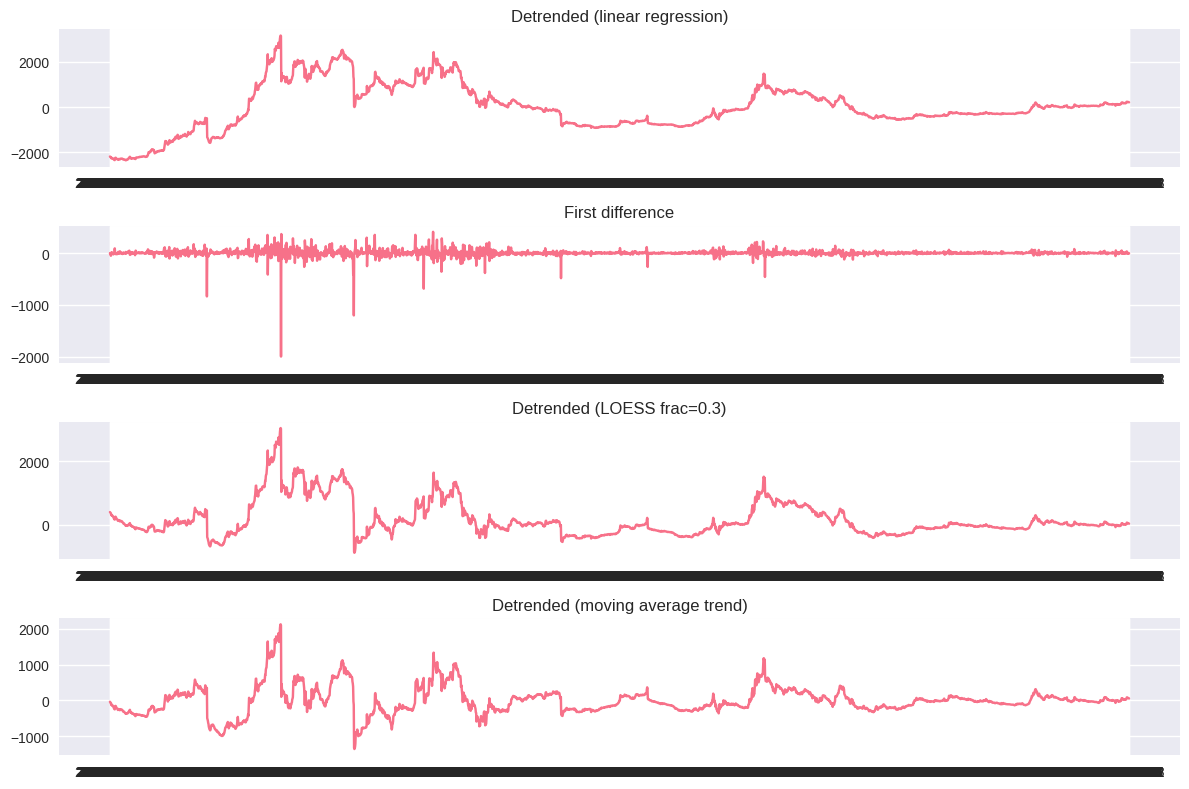

In [ ]:
#Plot detrended series for visual inspection
plt.figure(figsize=(12,8))
plt.subplot(4,1,1)
plt.plot(series.index, detrended_linear); plt.title('Detrended (linear regression)')
plt.subplot(4,1,2)
plt.plot(series.index[1:], diff1_series.iloc[1:]); plt.title('First difference')
plt.subplot(4,1,3)
plt.plot(series.index, detrended_loess_03); plt.title('Detrended (LOESS frac=0.3)')
plt.subplot(4,1,4)
plt.plot(series.index, detrended_moving_series); plt.title('Detrended (moving average trend)')
plt.tight_layout()
plt.show()

#3-- Seasonality Analysis
For datasets exhibiting seasonal patterns, conduct the following analyses:
(a) Create seasonal subseries plots by grouping data by season (month, quarter, etc.) and checking for consistent patterns

In [ ]:
# %% 4) SEASONALITY CHECK (if applicable)
# Our dataset seems to be irregular daily trading data for a portion of 2011; seasonality may not be relevant.
# But we'll attempt to check by month if month information exists.

# Ensure 'published_date' in df is datetime type first
df['published_date'] = pd.to_datetime(df['published_date'])
# Then extract the month and add it as a column to the DataFrame df
df['month'] = df['published_date'].dt.month

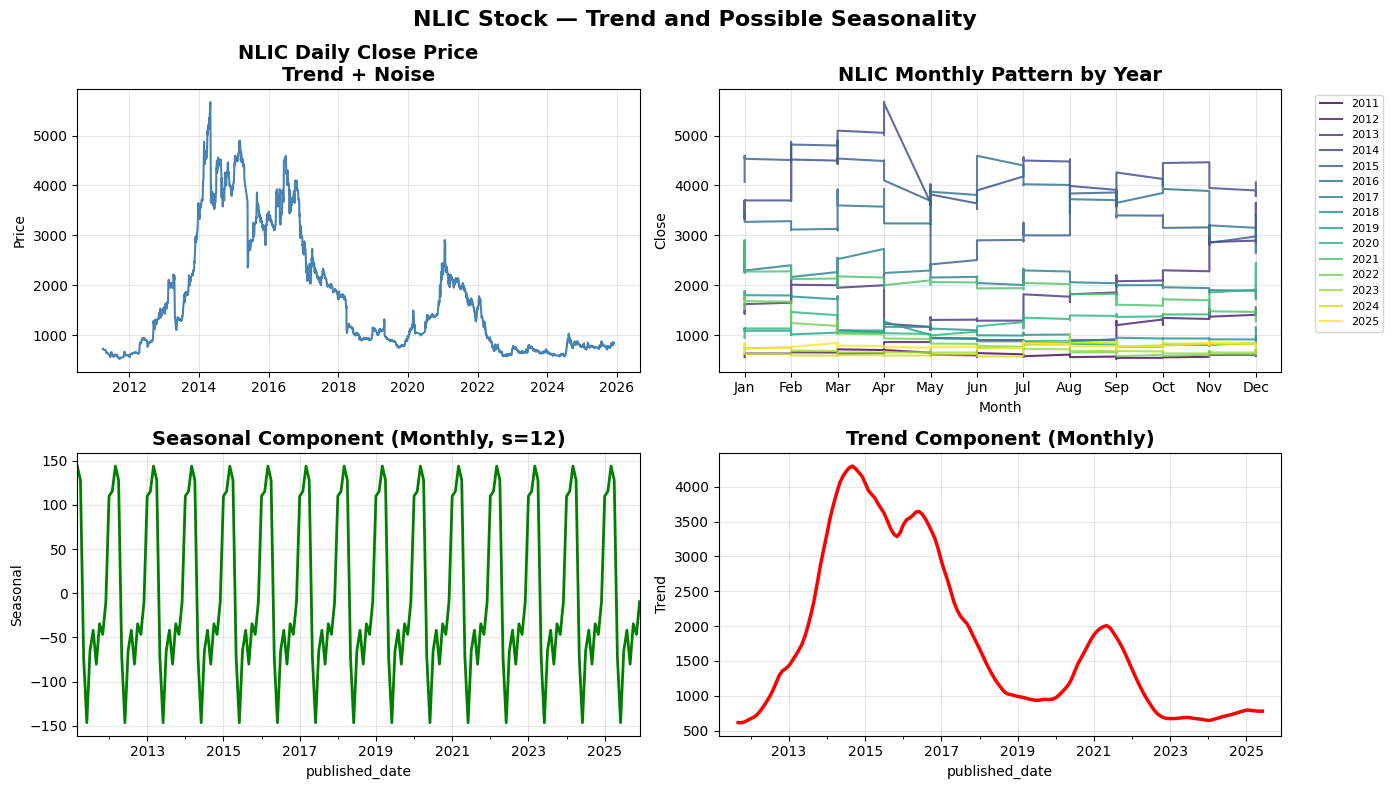

In [ ]:
plt.figure(figsize=(14, 8))

# 1) Raw data: shows overall behaviour
plt.subplot(2, 2, 1)
plt.plot(df[time_col], df[value_col], color='steelblue', linewidth=1.5)
plt.title('NLIC Daily Close Price\nTrend + Noise', fontsize=14, fontweight='bold')
plt.ylabel('Price')
plt.grid(alpha=0.3)

# 2) Year-by-year overlay to see monthly pattern (if any)
plt.subplot(2, 2, 2)
years = df[time_col].dt.year.unique()
colors = plt.cm.viridis(np.linspace(0, 1, len(years)))

for i, year in enumerate(years):
    yearly = df[df[time_col].dt.year == year]
    plt.plot(
        yearly[time_col].dt.month,
        yearly[value_col],
        color=colors[i],
        label=str(year),
        alpha=0.8
    )

plt.title('NLIC Monthly Pattern by Year', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel(value_col.capitalize())
plt.xticks(range(1, 13),
           ['Jan','Feb','Mar','Apr','May','Jun',
            'Jul','Aug','Sep','Oct','Nov','Dec'])
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.grid(alpha=0.3)

# 3) Seasonal component via decomposition (if you suspect yearly seasonality)
# period=12 assumes monthly seasonality on monthly data, so resample first:
monthly = series_daily.resample('M').mean()

decomp = seasonal_decompose(monthly, model='additive', period=12)

plt.subplot(2, 2, 3)
decomp.seasonal.plot(color='green', linewidth=2)
plt.title('Seasonal Component (Monthly, s=12)', fontsize=14, fontweight='bold')
plt.ylabel('Seasonal')
plt.grid(alpha=0.3)

# 4) Trend component from decomposition
plt.subplot(2, 2, 4)
decomp.trend.plot(color='red', linewidth=2.5)
plt.title('Trend Component (Monthly)', fontsize=14, fontweight='bold')
plt.ylabel('Trend')
plt.grid(alpha=0.3)

plt.suptitle('NLIC Stock — Trend and Possible Seasonality',
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

In [ ]:
# Seasonal subseries (month)
# Ensure the index is a proper DatetimeIndex by recreating the Series
series = pd.Series(series.values, index=pd.to_datetime(series.index))

monthly_means = series.groupby(series.index.month).mean()
print('Monthly means:')
print(monthly_means)

Monthly means:
published_date
1     1924.673477
2     1919.185039
3     1981.481705
4     1937.447769
5     1597.371092
6     1579.447331
7     1642.585655
8     1688.621541
9     1681.350517
10    1728.451316
11    1660.925725
12    1821.461679
dtype: float64


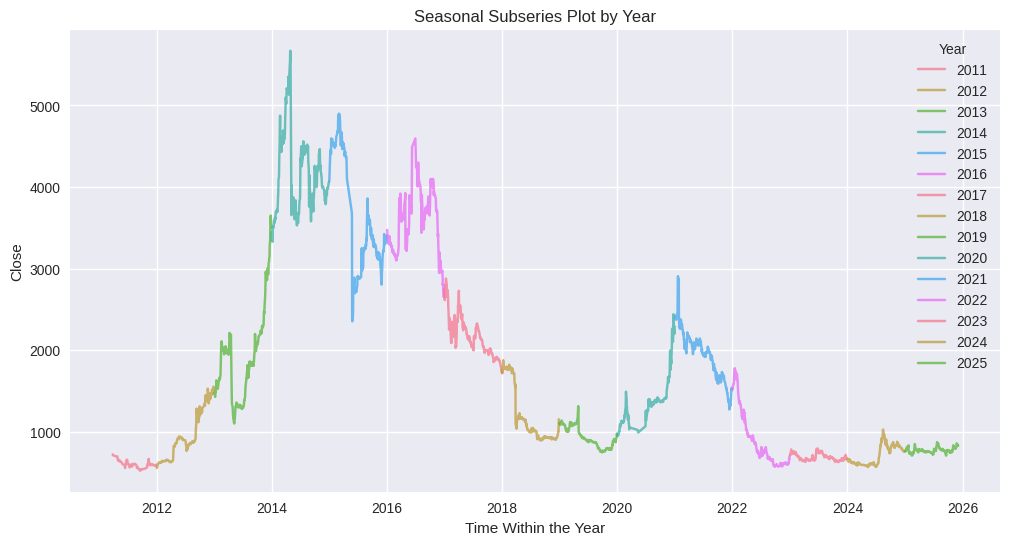

In [ ]:
#Seasonal Subseries Plot
#Group by Year
df['Year'] = df[time_col].dt.year

plt.figure(figsize=(12,6))

# Plot each year as its own line
for year, group in df.groupby('Year'):
    plt.plot(group[time_col], group[value_col], label=str(year), alpha=0.7)

plt.title("Seasonal Subseries Plot by Year")
plt.xlabel("Time Within the Year")
plt.ylabel(value_col.capitalize())
plt.legend(title="Year")
plt.show()

#(b) Autocorellation Function(ACF) for Seasonality

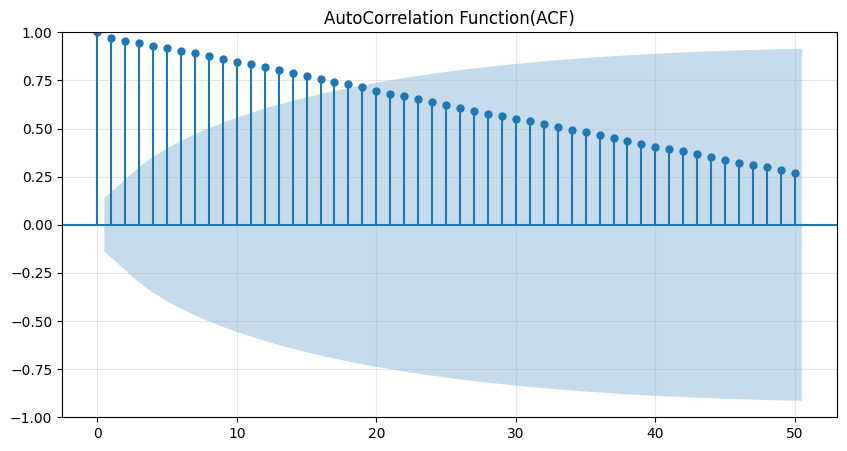

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plt.style.use('default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

np.random.seed(42)
n = 200
t = np.arange(n)

# CASE 1: Strong UPWARD trend → slow positive ACF decay
upward = 0.5 * t + np.random.normal(0, 4, n)
plot_acf(upward, lags=50);
plt.title("AutoCorrelation Function(ACF)")
plt.show()


#(c) Fourier Transform

Apply Fourier transform to identify dominant frequencies and convert them to seasonal periods


In [ ]:
# Fourier transform to detect dominant frequencies
y_f = series.values - np.mean(series.values)
freqs = np.fft.rfftfreq(len(y_f), d=1) # d=1 since t index is integer spacing
fft_vals = np.abs(np.fft.rfft(y_f))


Top frequency magnitudes and corresponding periods (in time steps):
1 freq= 0.00031486146095717883 period steps= 3176.0 magnitude= 1980337.0206508639
2 freq= 0.0006297229219143577 period steps= 1588.0 magnitude= 1471356.89546652
3 freq= 0.0012594458438287153 period steps= 794.0 magnitude= 560360.6734567761
4 freq= 0.0009445843828715365 period steps= 1058.6666666666667 magnitude= 427472.14309882786
5 freq= 0.001889168765743073 period steps= 529.3333333333334 magnitude= 403972.52877348434


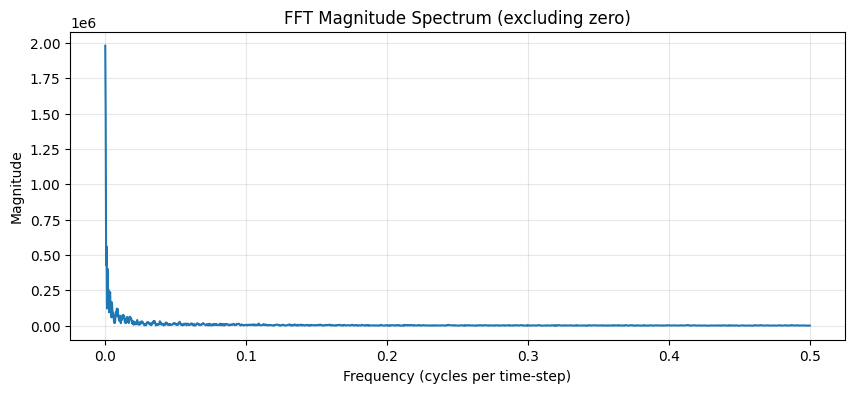

Dominant Frequency: 0.00031486146095717883
Estimated Seasonal Period: 3176.0


In [ ]:
# show top frequencies
idx_sorted = np.argsort(fft_vals)[::-1]
print('\nTop frequency magnitudes and corresponding periods (in time steps):')
for i in range(min(5, len(idx_sorted))):
    f = freqs[idx_sorted[i]]
    period = 1/f if f>0 else np.inf
    print(i+1, 'freq=', f, 'period steps=', period, 'magnitude=', fft_vals[idx_sorted[i]])

plt.figure(figsize=(10,4))
plt.plot(freqs[1:], fft_vals[1:])
plt.title('FFT Magnitude Spectrum (excluding zero)')
plt.xlabel('Frequency (cycles per time-step)')
plt.ylabel('Magnitude')
plt.show()
# ------------------------------------------------------------
# Mathematical Formulation of Fourier Transform:
#
# The Discrete Fourier Transform (DFT) is:
#
#     X(k) = Σ_{t=0}^{N-1} y_t * e^{-i 2π k t / N}
#
# A peak at frequency f means a repeating cycle of:
#
#     Period = 1 / f
#
# Example:
#     If f = 1/12 → Seasonal period = 12 months
# ------------------------------------------------------------

# Print dominant frequency
dominant_index = np.argmax(positive_fft_values[1:]) + 1
dominant_frequency = positive_freqs[dominant_index]
dominant_period = 1 / dominant_frequency

print("Dominant Frequency:", dominant_frequency)
print("Estimated Seasonal Period:", dominant_period)

#4 Stationary Tests for each detrended series

In [ ]:
from statsmodels.tsa.stattools import adfuller

def stationarity_tests(x, name='series'):
    x_nonan = x[~np.isnan(x)]
    print('\nStationarity tests for', name)
    if len(x_nonan) < 3:
        print('Series too short for tests')
        return None
    # ADF
    adf_res = adfuller(x_nonan, autolag='AIC')
    print('ADF test statistic =', adf_res[0])
    print('ADF p-value =', adf_res[1])
    print('ADF critical values:', adf_res[4])
    # KPSS
    try:
        kpss_res = kpss(x_nonan, regression='c', nlags='auto')
        print('KPSS test statistic =', kpss_res[0])
        print('KPSS p-value =', kpss_res[1])
        print('KPSS critical values:', kpss_res[3])
    except Exception as e:
        print('KPSS failed:', e)

In [ ]:
# Apply tests to all detrended variants
stationarity_tests(detrended_linear.values, 'detrended_linear')
stationarity_tests(diff1_series.values, 'first_difference')
stationarity_tests(detrended_loess_03.values, 'detrended_loess_03')
stationarity_tests(detrended_moving_series.values, 'detrended_moving')


Stationarity tests for detrended_linear
ADF test statistic = -2.5700805249939456
ADF p-value = 0.09934001587926422
ADF critical values: {'1%': np.float64(-3.432414543587629), '5%': np.float64(-2.8624521891581085), '10%': np.float64(-2.5672555792176257)}
KPSS test statistic = 0.6106871196299766
KPSS p-value = 0.021664807306365764
KPSS critical values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}

Stationarity tests for first_difference
ADF test statistic = -26.077918763154557
ADF p-value = 0.0
ADF critical values: {'1%': np.float64(-3.432414543587629), '5%': np.float64(-2.8624521891581085), '10%': np.float64(-2.5672555792176257)}
KPSS test statistic = 0.16219629406587768
KPSS p-value = 0.1
KPSS critical values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}

Stationarity tests for detrended_loess_03
ADF test statistic = -3.474393909332901
ADF p-value = 0.008669586325447114
ADF critical values: {'1%': np.float64(-3.432414543587629), '5%': np.float64(-2.86245218915810

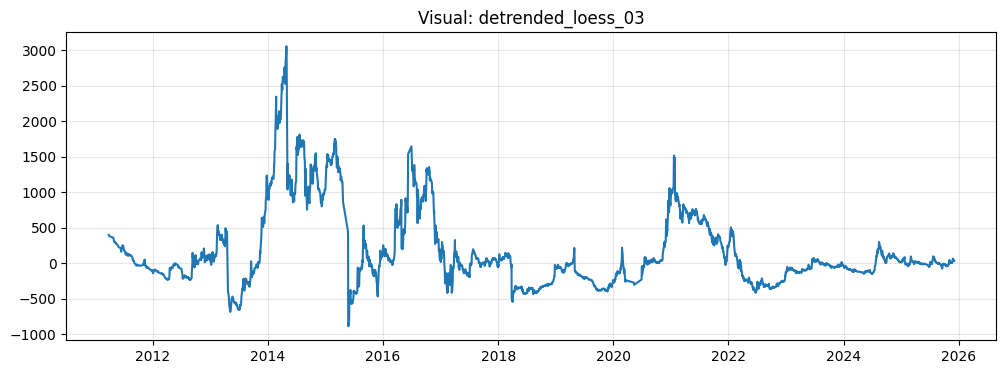

In [ ]:
# Visual inspection - histogram & rolling mean/variance for best candidate (choose one based on ADF/KPSS)
candidate = 'detrended_loess_03'
plt.figure(figsize=(12,4))
plt.plot(series.index, detrended_loess_03); plt.title(f'Visual: {candidate}')
plt.show()

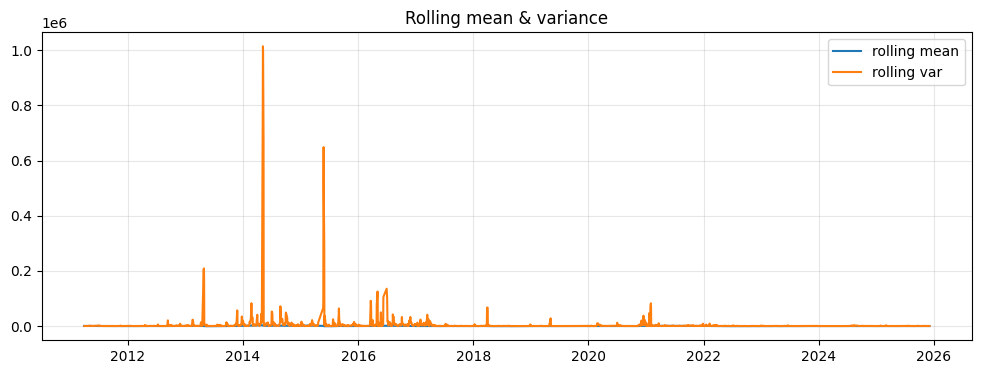

In [ ]:
# Rolling stats
rol_mean = detrended_loess_03.rolling(window=5, min_periods=1).mean()
rol_var = detrended_loess_03.rolling(window=5, min_periods=1).var()
plt.figure(figsize=(12,4))
plt.plot(series.index, rol_mean, label='rolling mean')
plt.plot(series.index, rol_var, label='rolling var')
plt.legend(); plt.title('Rolling mean & variance')
plt.show()

#Model Identification on Best Detrended Series

In [ ]:
# We'll pick the first difference (diff1) as a typical stationary candidate (subject to tests above)
model_series = diff1_series.dropna().reset_index(drop=True)

<Figure size 1000x400 with 0 Axes>

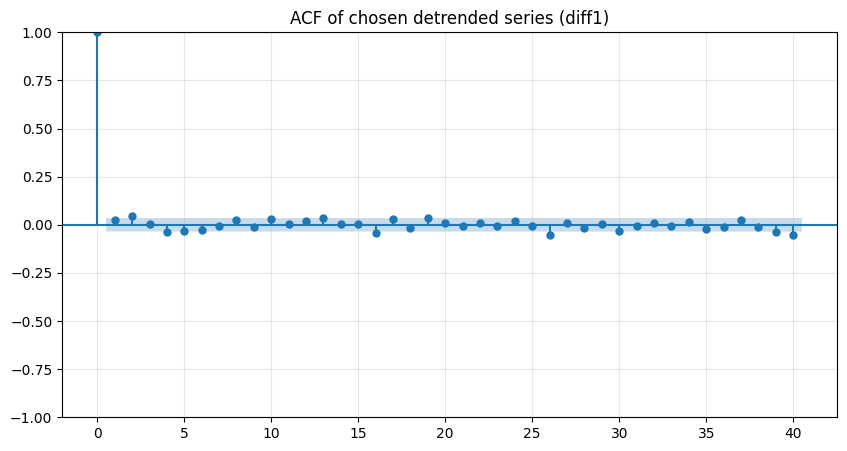

<Figure size 1000x400 with 0 Axes>

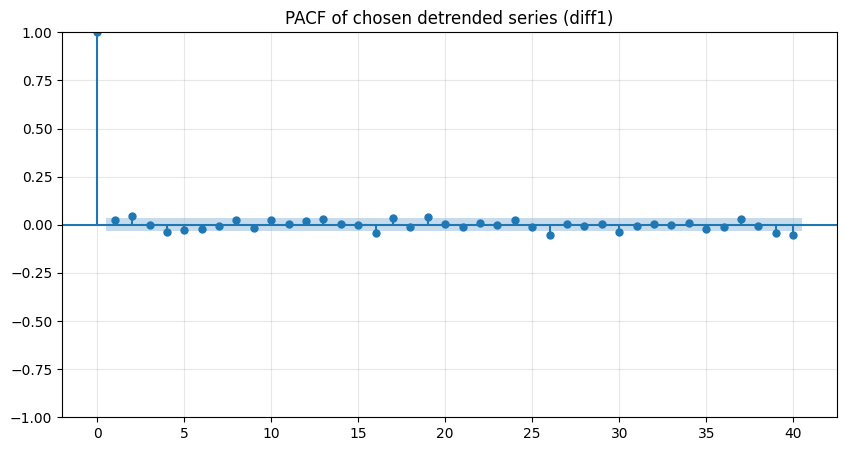

In [ ]:
# plot ACF and PACF
plt.figure(figsize=(10,4))
plot_acf(model_series, lags=40)
plt.title('ACF of chosen detrended series (diff1)')
plt.show()

plt.figure(figsize=(10,4))
plot_pacf(model_series, lags=40)
plt.title('PACF of chosen detrended series (diff1)')
plt.show()

In [ ]:
# Use auto-grid search for ARIMA (small grid) based on AIC/BIC
best_aic = np.inf
best_order = None
best_model = None

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# we'll try p in 0..3, d=0 (already differenced), q in 0..3
for p in range(0,4):
    for q in range(0,4):
        try:
            mod = SARIMAX(model_series, order=(p,0,q), enforce_stationarity=False, enforce_invertibility=False)
            res = mod.fit(disp=False)
            if res.aic < best_aic:
                best_aic = res.aic
                best_order = (p,0,q)
                best_model = res
        except Exception as e:
            continue

print('\nBest ARIMA candidate based on AIC: order=', best_order, 'AIC=', best_aic)
print(best_model.summary())


Best ARIMA candidate based on AIC: order= (2, 0, 3) AIC= 35744.5161008578
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 3175
Model:               SARIMAX(2, 0, 3)   Log Likelihood              -17866.258
Date:                Mon, 08 Dec 2025   AIC                          35744.516
Time:                        03:59:29   BIC                          35780.887
Sample:                             0   HQIC                         35757.562
                               - 3175                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.2101      0.140      8.614      0.000       0.935       1.485
ar.L2         -0.5638      0.146     -3.860      0.000  

In [ ]:
# Split into train/test
train_size = int(0.8*len(model_series))
train, test = model_series[:train_size], model_series[train_size:]

In [ ]:
# Refit best model on train and forecast
p,q = best_order[0], best_order[2]
model_final = SARIMAX(train, order=(p,0,q), enforce_stationarity=False, enforce_invertibility=False)
res_final = model_final.fit(disp=False)

In [ ]:
# Forecast
n_forecast = len(test)
pred = res_final.get_forecast(steps=n_forecast)
pred_mean = pred.predicted_mean
pred_ci = pred.conf_int(alpha=0.05)

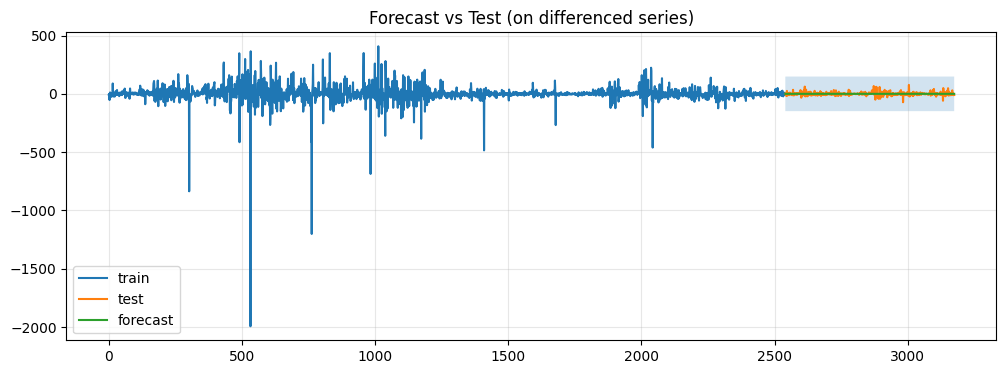

In [ ]:
# Compare predictions
plt.figure(figsize=(12,4))
plt.plot(train.index, train, label='train')
plt.plot(np.arange(len(train), len(train)+len(test)), test.values, label='test')
plt.plot(np.arange(len(train), len(train)+len(test)), pred_mean, label='forecast')
plt.fill_between(np.arange(len(train), len(train)+len(test)), pred_ci.iloc[:,0], pred_ci.iloc[:,1], alpha=0.2)
plt.legend()
plt.title('Forecast vs Test (on differenced series)')
plt.show()

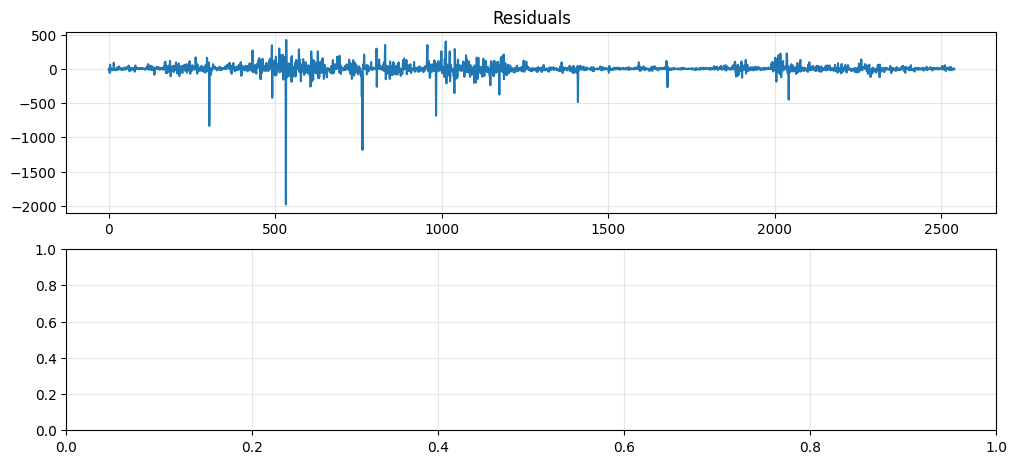

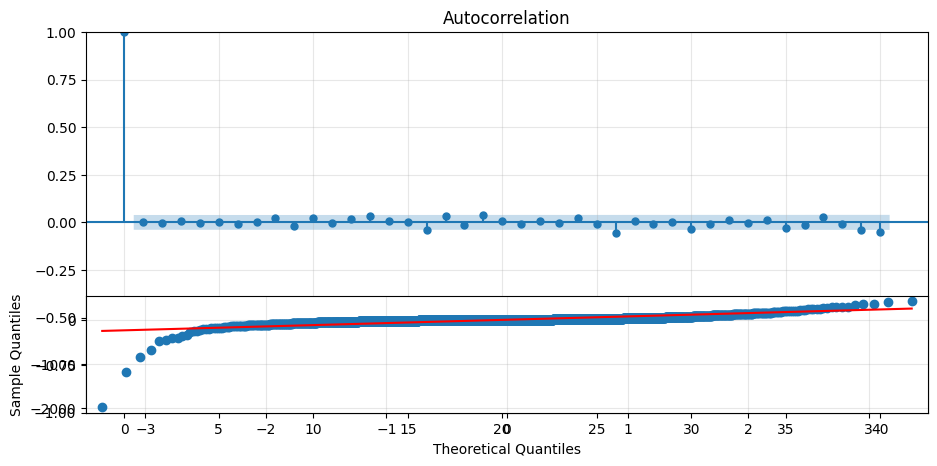

In [ ]:
# Residual diagnostics
resid_final = res_final.resid
plt.figure(figsize=(12,8))
plt.subplot(3,1,1)
plt.plot(resid_final); plt.title('Residuals')
plt.subplot(3,1,2)
plot_acf(resid_final, lags=40, alpha=0.05)
plt.subplot(3,1,3)
sm.qqplot(resid_final, line='s', ax=plt.gca())
plt.tight_layout()
plt.show()

In [ ]:
# Ljung-Box test
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(resid_final, lags=[10,20], return_df=True)
print('\nLjung-Box test (residuals):')
print(lb)


Ljung-Box test (residuals):
      lb_stat  lb_pvalue
10   3.983579   0.948085
20  19.173506   0.510575


In [ ]:
# Normality tests
shapiro_p = stats.shapiro(resid_final)[1] if len(resid_final) < 5000 else (None)
jb_stat, jb_p = stats.jarque_bera(resid_final)
print('\nNormality tests: Shapiro p-value=', shapiro_p, 'Jarque-Bera p-value=', jb_p)


Normality tests: Shapiro p-value= 1.9960528080028153e-63 Jarque-Bera p-value= 0.0


In [ ]:
# %% 7) RNN METHODS (only if enough data points)
if len(series) > 500:
# Placeholder: show data preparation and model sketches
    print('\nData long enough for RNN methods. Prepare sequences, normalize, split train/test, build LSTM/GRU with Keras.')
else:
    print('\nDataset too small for RNN training recommendation (<500 points). Skipping RNN implementation.')

# %% 8) NOTES, REPRODUCIBILITY & SUBMISSION
# - Random seeds are set at top.
# - All computations for linear regression and Mann-Kendall are done with explicit math (no black-box formula calls).
# - LOESS is implemented manually using tricube weights and local linear regressions.
# - EWMA implemented with explicit recursion.
# - For stationarity tests (ADF, KPSS) and ARIMA model fitting, we used statsmodels implementations to ensure numerical reliability.

print('\nNotebook run complete. Inspect intermediate plots and printed outputs for your report. Ensure NLIC.csv path matches Kaggle environment.')


Data long enough for RNN methods. Prepare sequences, normalize, split train/test, build LSTM/GRU with Keras.

Notebook run complete. Inspect intermediate plots and printed outputs for your report. Ensure NLIC.csv path matches Kaggle environment.


#Data Preparation for MOdels

In [ ]:
# Use close price
values = series.values.astype('float32')

# Manual Min-Max Scaling (no sklearn)
min_v = values.min()
max_v = values.max()
scaled = (values - min_v) / (max_v - min_v)

# Create sequences
def create_sequences(data, seq_len=20):
    X, Y = [], []
    for i in range(len(data)-seq_len):
        X.append(data[i:i+seq_len])
        Y.append(data[i+seq_len])
    return np.array(X), np.array(Y)

seq_len = 20
X, y = create_sequences(scaled, seq_len)

# Train/test split
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Reshape for RNNs: (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test  = X_test.reshape((X_test.shape[0],  X_test.shape[1],  1))

#LSTM Model

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM

tf.random.set_seed(42)

lstm_model = Sequential()
lstm_model.add(LSTM(50, activation='tanh', input_shape=(seq_len,1)))
lstm_model.add(Dense(1))

lstm_model.compile(optimizer='adam', loss='mse')

history = lstm_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0385 - val_loss: 3.0190e-04
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0011 - val_loss: 2.5030e-04
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 9.7568e-04 - val_loss: 1.8640e-04
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 9.2145e-04 - val_loss: 1.3632e-04
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 8.7029e-04 - val_loss: 1.0421e-04
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 8.2325e-04 - val_loss: 8.7613e-05
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.8230e-04 - val_loss: 7.9299e-05
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.4874e-04 - val_loss: 7.4320e-05
Epoch 9/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.1992e-04 - val_loss: 7.0276e-05
Epoch 10/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 6.9408e-04 - val_loss: 6.6658e-05
Epoch 11/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 6.7132e-04 - val_

#GRU Model

In [ ]:
from tensorflow.keras.layers import GRU

gru_model = Sequential()
gru_model.add(GRU(50, activation='tanh', input_shape=(seq_len,1)))
gru_model.add(Dense(1))

gru_model.compile(optimizer='adam', loss='mse')

gru_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0423 - val_loss: 4.4912e-05
Epoch 2/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 6.7120e-04 - val_loss: 8.6537e-05
Epoch 3/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 5.4440e-04 - val_loss: 6.1261e-05
Epoch 4/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 5.0448e-04 - val_loss: 4.5147e-05
Epoch 5/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 4.7423e-04 - val_loss: 3.8213e-05
Epoch 6/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 4.4999e-04 - val_loss: 3.5125e-05
Epoch 7/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 4.3009e-04 - val_loss: 3.3400e-05
Epoch 8/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 4.1340e-04 - val_loss: 3.2216e-05
Epoch 9/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 3.9907e-04 - val_loss: 3.1244e-05
Epoch 10/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 3.8655e-04 - val_loss: 3.0354e-05
Epoch 11/20
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 3.7556e-04 - 

#Model Evaluation

In [ ]:
# LSTM predictions
lstm_pred = lstm_model.predict(X_test)

# GRU predictions
gru_pred = gru_model.predict(X_test)

# Rescale back
y_test_real = y_test * (max_v - min_v) + min_v
lstm_real = lstm_pred * (max_v - min_v) + min_v
gru_real  = gru_pred * (max_v - min_v) + min_v

# RMSE calculation (manual)
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

print("LSTM RMSE:", rmse(y_test_real, lstm_real))
print("GRU RMSE :", rmse(y_test_real, gru_real))

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
LSTM RMSE: 123.15103
GRU RMSE : 125.82026


#Plot Comoarision

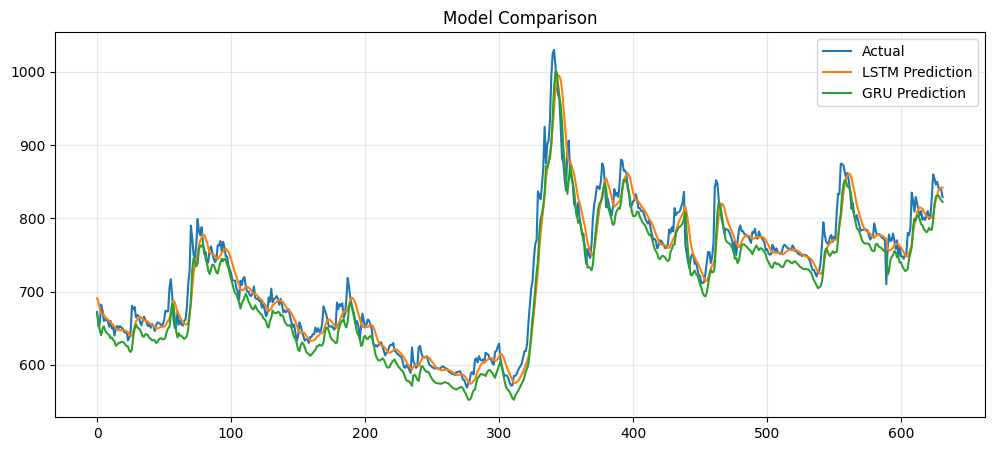

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(y_test_real, label='Actual')
plt.plot(lstm_real, label='LSTM Prediction')
plt.plot(gru_real, label='GRU Prediction')
plt.legend()
plt.title("Model Comparison")
plt.show()

In [ ]:
# Baseline model
from sklearn.metrics import mean_squared_error
import numpy as np

train_size = int(len(series) * 0.8)
train = series[:train_size]
test  = series[train_size:]

naive_forecast = np.repeat(train.iloc[-1], len(test))
rmse = np.sqrt(mean_squared_error(test, naive_forecast))
print("Naive RMSE:", rmse)

Naive RMSE: 91.00847674683867


#Custom Linear Regression for Time Series

In [ ]:
def create_lags(df, col='close', lag=5):
    data = df.copy()
    for i in range(1, lag+1):
        data[f'lag_{i}'] = data[col].shift(i)
    return data.dropna()

# Convert the series to a DataFrame, explicitly naming the column 'close'
temp_df = series.to_frame(name='close')

lagged = create_lags(temp_df, col='close')

X = lagged.drop(['close'], axis=1)
y = lagged['close']

In [ ]:
split = int(len(X)*0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [ ]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

y_pred = model_lr.predict(X_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred))
print("Custom Lag Model RMSE:", rmse_lr)

Custom Lag Model RMSE: 14.008091792422949


#ARIMA

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

model_arima = ARIMA(train, order=(5,1,0))
model_arima = model_arima.fit()

forecast_arima = model_arima.forecast(steps=len(test))
rmse_arima = np.sqrt(mean_squared_error(test, forecast_arima))
print("ARIMA RMSE:", rmse_arima)

ARIMA RMSE: 90.83295087931339


#LSTM(Best For Large Data)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

scaler = MinMaxScaler()
scaled = scaler.fit_transform(series.values.reshape(-1, 1))

def create_sequences(data, window=10):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])
    return np.array(X), np.array(y)

X_seq, y_seq = create_sequences(scaled)

split = int(len(X_seq) * 0.8)
X_train, X_test = X_seq[:split], X_seq[split:]
y_train, y_test = y_seq[:split], y_seq[split:]

model = Sequential()
model.add(LSTM(50, return_sequences=False, input_shape=(X_train.shape[1], 1)))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=20, batch_size=32)

pred = model.predict(X_test)
pred = scaler.inverse_transform(pred)
y_test_real = scaler.inverse_transform(y_test)

rmse_lstm = np.sqrt(mean_squared_error(y_test_real, pred))
print("LSTM RMSE:", rmse_lstm)

Epoch 1/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0330
Epoch 2/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 8.4155e-04
Epoch 3/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 8.1286e-04
Epoch 4/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.9378e-04
Epoch 5/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.7486e-04
Epoch 6/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.5527e-04
Epoch 7/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.3436e-04
Epoch 8/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7.1180e-04
Epoch 9/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6.8762e-04
Epoch 10/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6.6207e-04
Epoch 11/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.3546e-04
Epoch 12/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6.0811e-04
Epoch 13/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 5.8039e-04
Epoch 14/20
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 5.5278e-04
Epoch 15/20
80/80 ━━━━━━━━━━━━

#Model Comparision

In [ ]:
print("MODEL COMPARISON:")
print("Naive RMSE:", rmse)
print("Linear Regression (Custom):", rmse_lr)
print("ARIMA:", rmse_arima)
print("LSTM:", rmse_lstm)

MODEL COMPARISON:
Naive RMSE: 91.00847674683867
Linear Regression (Custom): 14.008091792422949
ARIMA: 90.83295087931339
LSTM: 26.237961786686377


Plotting Actual v/s Predicted--For all models

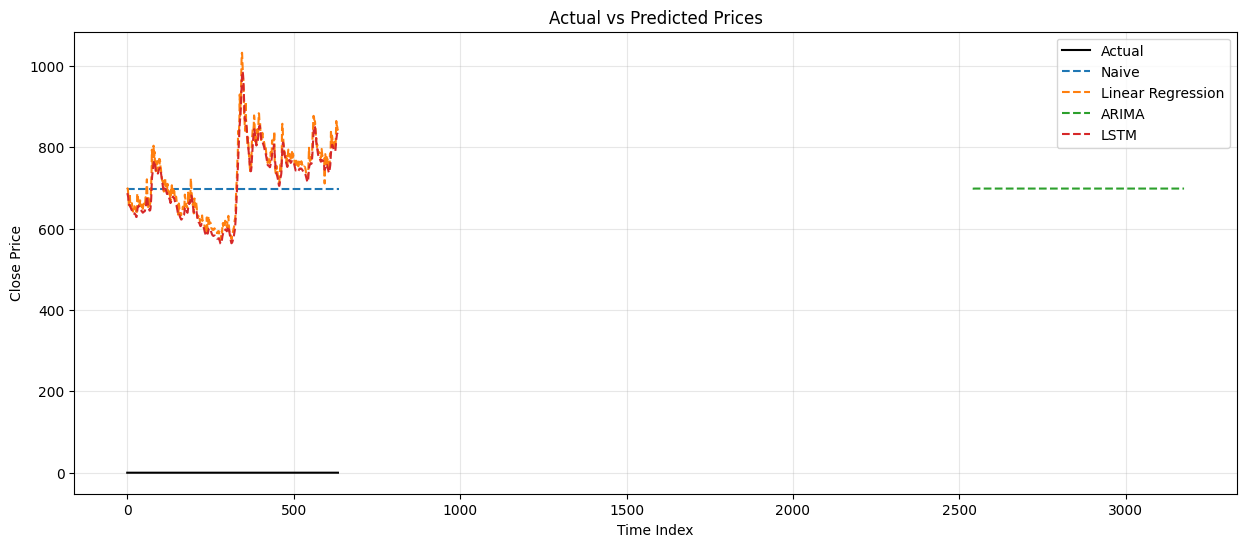

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

# Actual values
plt.plot(y_test, label='Actual', color='black')

# Model predictions
plt.plot(naive_forecast, label='Naive', linestyle='--')
plt.plot(y_pred, label='Linear Regression', linestyle='--')
plt.plot(forecast_arima, label='ARIMA', linestyle='--')
plt.plot(pred.flatten(), label='LSTM', linestyle='--')

plt.title("Actual vs Predicted Prices")
plt.xlabel("Time Index")
plt.ylabel("Close Price")
plt.legend()
plt.show()

#Plot: RMSE Comparision

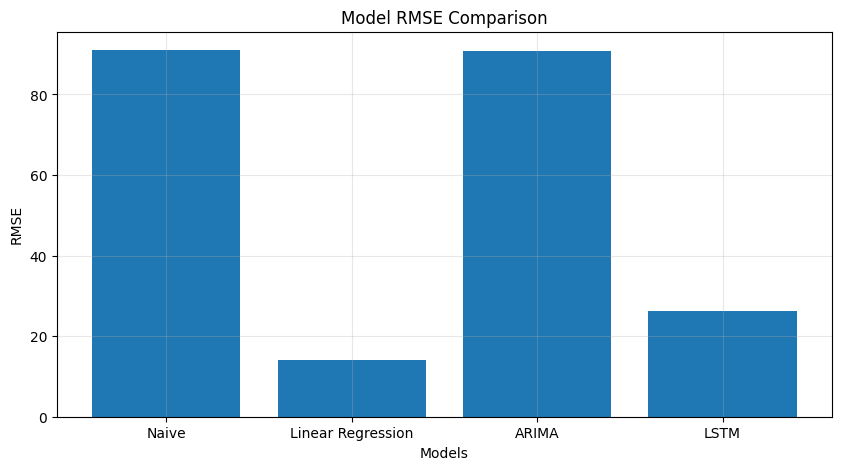

In [ ]:
models = ['Naive', 'Linear Regression', 'ARIMA', 'LSTM']
rmse_values = [rmse, rmse_lr, rmse_arima, rmse_lstm]

plt.figure(figsize=(10,5))
plt.bar(models, rmse_values)
plt.title("Model RMSE Comparison")
plt.xlabel("Models")
plt.ylabel("RMSE")
plt.show()